In [ ]:
from typing import TypedDict, List, Annotated
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from langgraph.types import Send                                         # dynamically send tasks to worker nodes
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import SystemMessage, HumanMessage
from pathlib import Path
import operator
import re

In [ ]:
# Define the structure of a single task using Pydantic
class Task(BaseModel):
    id: int
    title: str
    brief: str = Field(..., description="What to cover")

    # Brief describes what the worker should cover in this section

In [72]:
# Define the structure of the complete blog plan
class Plan(BaseModel):
    blog_title: str
    tasks: List[Task]            # List of sections generated by the orchestrator

In [73]:
class State(TypedDict):
    topic: str
    plan: Plan
    
    # reducer: results from workers get concatenated automatically
    sections: Annotated[List[str], operator.add]
    final: str

In [74]:
llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

In [75]:
def orchestrator(state: State) -> dict:

    # Ask the LLM to generate output matching the Plan Pydantic schema
    plan = llm.with_structured_output(Plan).invoke(
        [
            SystemMessage(
                content="Create a blog plan with 5 - 7 sections on the following topic."
            ),
            HumanMessage(
                content=f"Topic: {state['topic']}"
            ),
        ]
    )

    return {"plan": plan}

In [76]:
# Dynamically creates a separate worker task for every planned section
def fanout(state: State):

    # Send each task to the worker node along with the required context
    return [
        Send(
            "worker", 
            {
                "task": task, 
                "topic": state["topic"], 
                "plan": state["plan"]
            },
        )
        for task in state["plan"].tasks
    ]

In [77]:
# Each worker independently writes one section of the blog
def worker(payload: dict) -> dict:

    # Extract the data sent to this worker by the fan-out function
    task = payload["task"]
    topic = payload["topic"]
    plan = payload["plan"]

    # Get the overall blog title from the generated plan
    blog_title = plan.blog_title

    response = llm.invoke(
        [
            # Define the worker's task
            SystemMessage(content="Write one clean Markdown section."),
            
            # Provide the blog context and section-specific instructions
            HumanMessage(
                content=(
                    f"Blog: {blog_title}\n"
                    f"Topic: {topic}\n\n"
                    f"Section: {task.title}\n\n"
                    f"Brief: {task.brief}\n\n"
                    "Return only the section content in Markdown."
                )
            )
        ]
    )

    content = response.content

    if isinstance(content, list):
        section_md = "\n".join(
            item["text"] if isinstance(item, dict) and "text" in item else str(item)
            for item in content
        ).strip()
    else:
        section_md = content.strip()

    # Return the generated section as a list
    # The sections reducer will combine results from parallel workers
    return {"sections": [section_md]}

In [79]:
# Combines all generated sections and creates the final blog
def reducer(state: State) -> dict:

    title = state["plan"].blog_title
    body = "\n\n".join(state["sections"]).strip()

    final_md = f"# {title}\n\n{body}\n"

    # Generate a short filename dynamically from the blog title
    words = re.findall(r"[a-zA-Z0-9]+", title.lower())
    filename = "_".join(words[:4]) + ".md"

    output_path = Path.cwd() / filename

    # Write the blog content into the file
    output_path.write_text(final_md, encoding="utf-8")

    return {"final": final_md}

In [80]:
graph = StateGraph(State)

graph.add_node("orchestrator", orchestrator)
graph.add_node("worker", worker)
graph.add_node("reducer", reducer)

In [81]:
graph.add_edge(START, "orchestrator")
graph.add_conditional_edges("orchestrator", fanout, ["worker"])
graph.add_edge("worker", "reducer")
graph.add_edge("reducer", END)

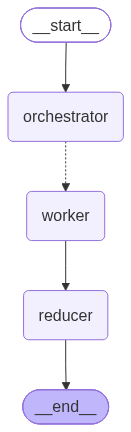

In [82]:
app = graph.compile()

app

In [83]:
output = app.invoke(
    {
        "topic": "write a blog on Discipline",
        "sections": []
    }
)

In [84]:
print(output["final"])

# The Power of Discipline: Building the Foundation for Lasting Success

## Introduction to Discipline

When most of us hear the word "discipline," our minds instantly conjure images of strict rules, agonizing self-denial, and rigid punishment. We picture a drill sergeant barking orders or a miserable diet that strips all joy from eating. Because of this cultural conditioning, we view discipline as the enemy of happiness—a heavy chain we must drag through life if we want to achieve anything worthwhile. 

But this is a profound misunderstanding. 

True discipline is not about punishing yourself; it is about respecting yourself. It is not a cage designed to restrict your movement, but rather the scaffolding that holds up the structure of your dreams. Far from being the opposite of freedom, discipline is actually its ultimate prerequisite. Think about it: the person who lacks financial discipline is a slave to debt and endless financial anxiety. The person who lacks physical discipline is 